# Assinatura de HSC em célula única e abundância em pseudo-bulk (GSE139369)

Este notebook percorre o estudo passo a passo, chamando as funções da pasta `R/`. O `main.R` faz o mesmo de uma vez e grava tudo em `reports/`. Os números são idênticos aos do README. São necessários cerca de 4 GB de memória.

In [1]:
if (basename(getwd()) == "notebooks") setwd("..")
suppressPackageStartupMessages(for (f in list.files("R", pattern = "\\.R$", full.names = TRUE)) source(f))
options(repr.plot.width = 9, repr.plot.height = 5)
set.seed(CONFIG$seed)

## 1. Dados e compartimento CD34+

In [2]:
granja <- load_granja(download_if_missing(CONFIG$granja_url))
all_cells <- granja$cells
compartment <- cd34_compartment(granja)
rm(granja); invisible(gc())
table(compartment$cells$donor, ifelse(compartment$cells$is_hsc, "HSC", "progenitor"))

    
      HSC progenitor
  D1  206       1640
  D2  612       1511
  D3  603       4223

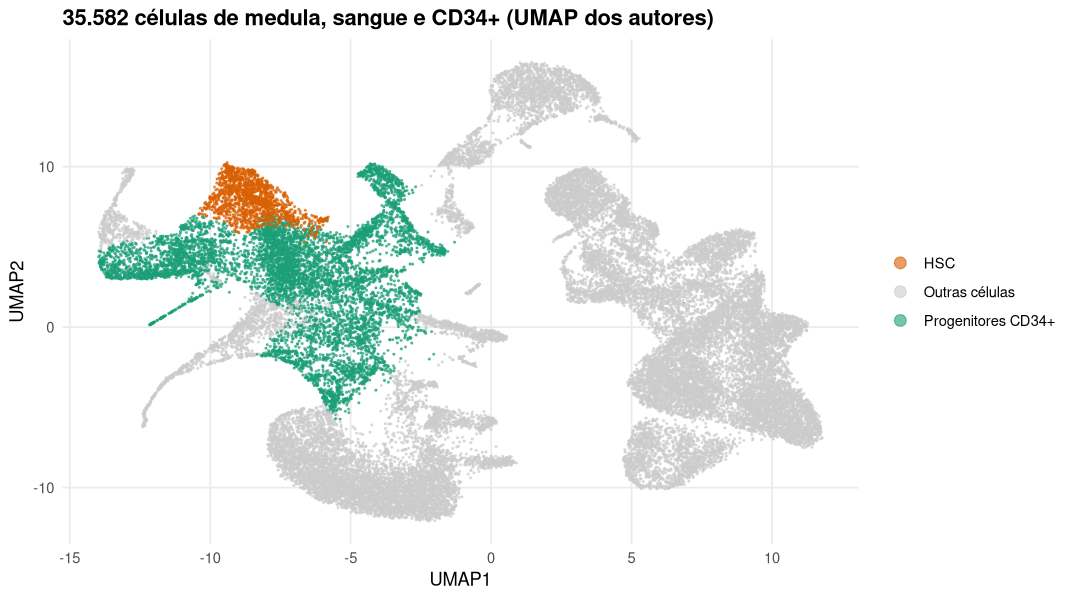

In [3]:
plot_umap(all_cells)

## 2. Pseudo-bulk pareado por doador e pseudorreplicação

A réplica biológica é o doador, não a célula. O teste célula a célula aparece só para medir o tamanho da distorção.

FDR < 5%: pseudo-bulk 2947 genes contra 5650 por célula


Altos em HSC: MEG3 HLF HOPX AVP CRHBP RBPMS PCDH9 PRSS1 NRIP1 SKAP1 IDS CLEC9A EMCN MECOM GATA3 HEMGN BCL2A1 CD52 TM4SF1 LIMCH1 


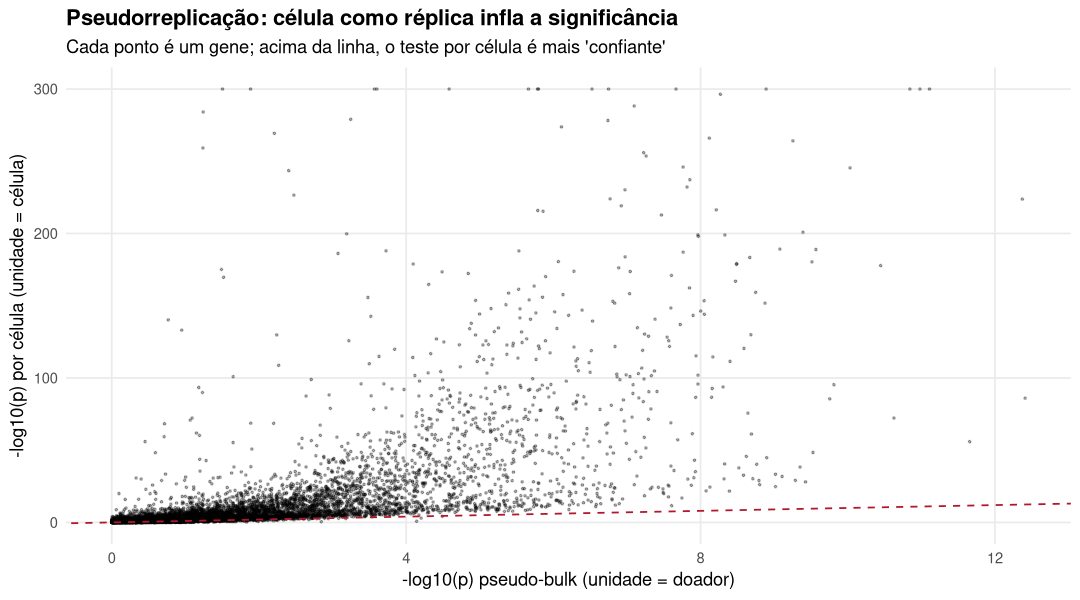

In [4]:
de <- pseudobulk_de(compartment)
signature <- build_signature(de$table)
cell_de <- cell_level_welch(compartment, de$table$gene)
cat(sprintf("FDR < 5%%: pseudo-bulk %d genes contra %d por célula\n",
            sum(de$table$fdr < 0.05), sum(cell_de$fdr < 0.05)))
cat("Altos em HSC:", head(signature$up, 20), "\n")
plot_pseudoreplication(de$table, cell_de)

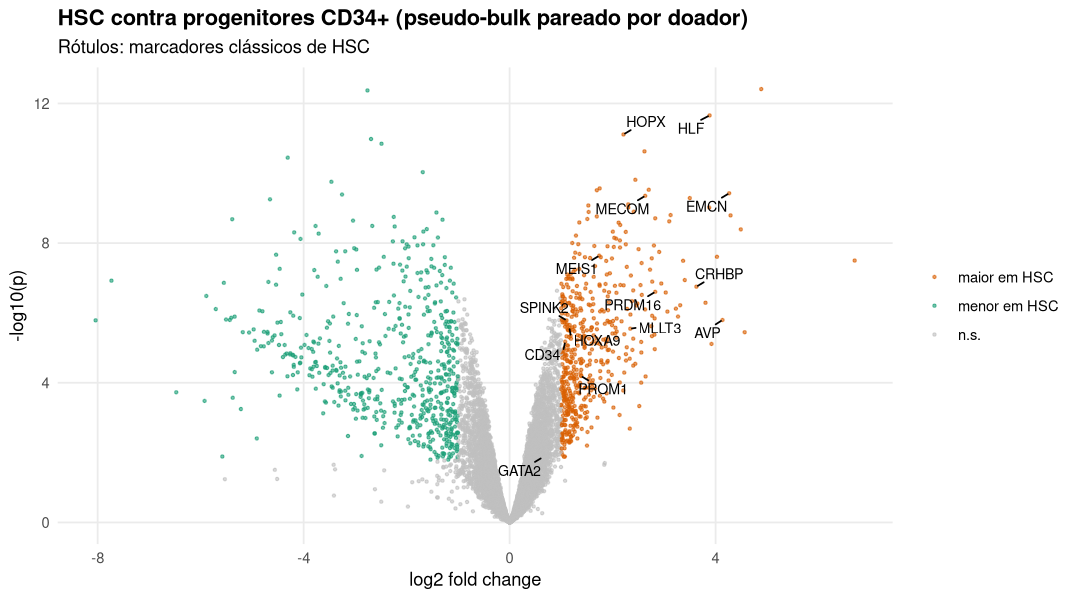

In [5]:
plot_volcano(de$table)

## 3. A assinatura funciona num doador novo? (nível de célula)

In [6]:
cells_lodo <- cell_level_lodo(compartment)
cells_lodo$summary

donor,n_hsc,n_progenitor,auc_signature,ci_low,ci_high,auc_markers,markers_ci_low,markers_ci_high,null_q95,p_random
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
D1,206,1640,0.9935665,0.9909688,0.9961642,0.9820803,0.9765877,0.9875729,0.6855515,0.000999001
D2,612,1511,0.9670088,0.9601431,0.9738746,0.9395830,0.9293763,0.9497898,0.5996092,0.000999001
D3,603,4223,0.9767890,0.9730246,0.9805535,0.9414517,0.9334109,0.9494925,0.6149532,0.000999001


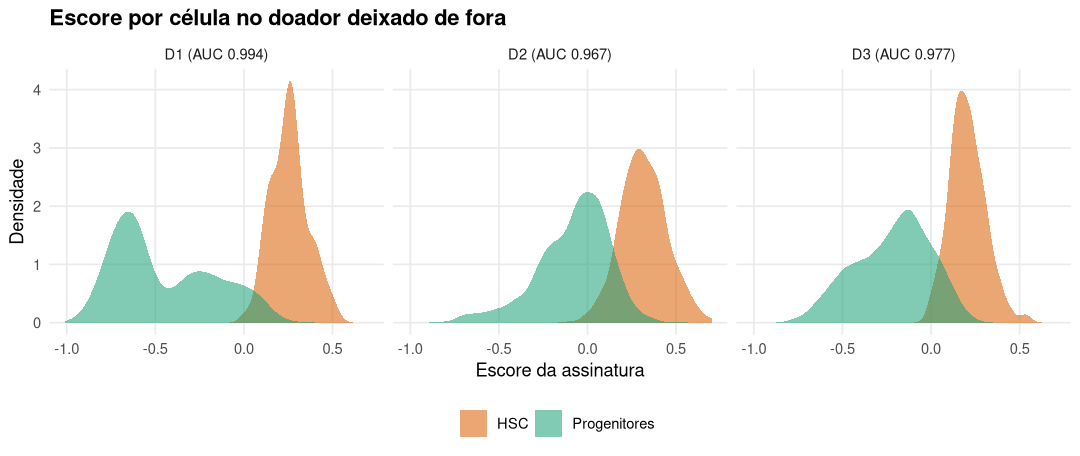

In [7]:
options(repr.plot.height = 3.8)
plot_cell_scores(cells_lodo$scores, cells_lodo$summary)

## 4. Fração de HSC em pseudo-bulks de células reais (doador deixado de fora)

In [8]:
options(repr.plot.height = 4.5)
pred <- pseudobulk_lodo(compartment)
metric_table(pred)

model,RMSE,MAE,Pearson,CCC,C_index
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
baseline,0.08474847,0.07308142,0.05639154,0.005075131,0.5180891
glmnet,0.04654007,0.03788952,0.85684035,0.840062267,0.8331886
nnls,0.12073177,0.09914034,0.50460504,0.445864430,0.6833931
signature,0.07057757,0.05667707,0.59179479,0.567242919,0.7062903


In [9]:
ci <- bootstrap_rmse(pred)
best <- ci$model[ci$model != "baseline"][which.min(ci$estimate[ci$model != "baseline"])]
print(ci)
paired_tests(pred, best)

      model   estimate     ci_low    ci_high
1  baseline 0.08474847 0.08186187 0.08778187
2    glmnet 0.04654007 0.04422253 0.04869254
3      nnls 0.12073177 0.11545384 0.12584033
4 signature 0.07057757 0.06683784 0.07467796


comparison,median_diff,p_value,donors_better,n_donors,p_holm
<chr>,<dbl>,<dbl>,<int>,<int>,<dbl>
glmnet vs baseline,-0.02874850,1.625930e-45,3,3,3.251859e-45
glmnet vs signature,-0.01319130,1.431178e-22,3,3,1.431178e-22
glmnet vs nnls,-0.05525164,1.022444e-68,3,3,3.067333e-68


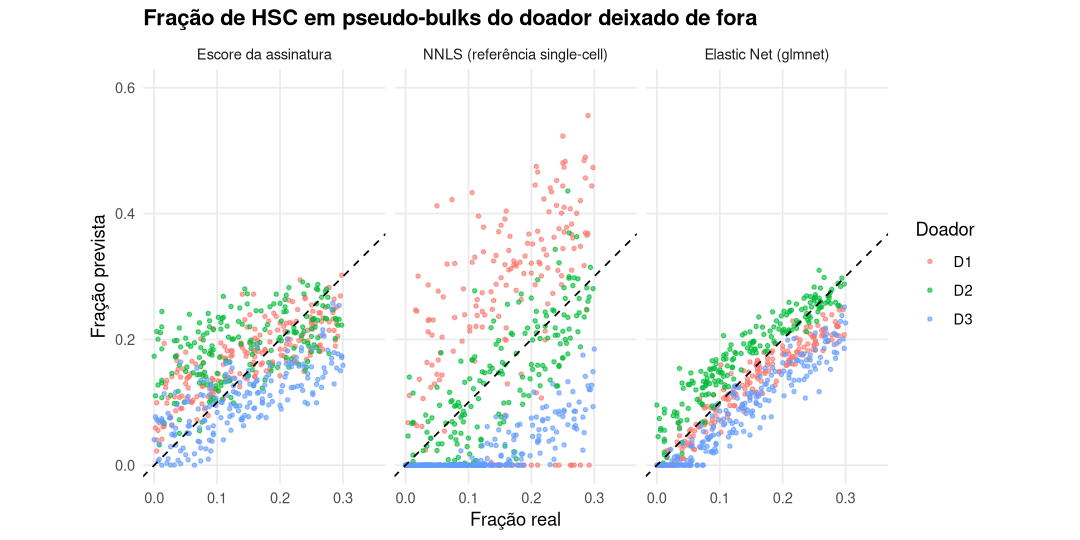

In [10]:
plot_predicted(pred)

## 5. De célula única para RNA-seq bulk (GSE74246)

AUC 0.978 (p aleatório = 0.0040); HSC vs. MPP: p = 0.171


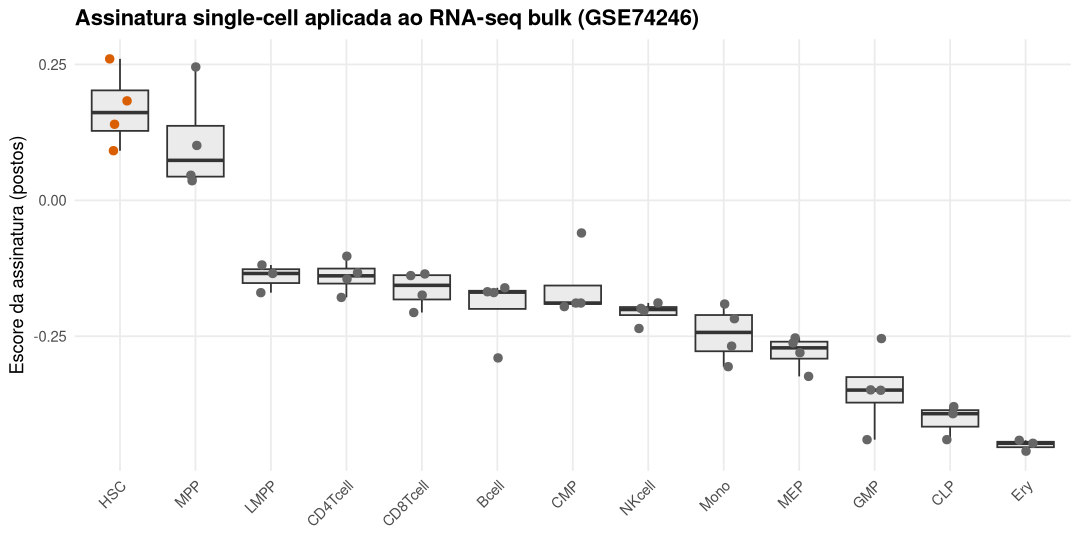

In [11]:
external <- external_validation(read_corces(download_if_missing(CONFIG$corces_counts_url)), signature)
cat(sprintf("AUC %.3f (p aleatório = %.4f); HSC vs. MPP: p = %.3f\n", external$auc, external$p_random,
            external$hsc_vs_mpp_p))
plot_external(external$scores)

## 6. Conclusões

* O pseudo-bulk pareado acha 516 genes altos e 588 baixos em HSC. O teste por célula declara quase o dobro de genes significativos (5.650 contra 2.947): isso é pseudorreplicação, não biologia extra.
* Em doadores novos, a assinatura separa HSC de progenitores com AUC de 0,97 a 0,99, acima dos marcadores clássicos e de 1.000 conjuntos aleatórios.
* O Elastic Net estima a fração de HSC num doador novo com RMSE de 0,047 (IC 95% de 0,044 a 0,049) e vence os outros métodos nos três doadores.
* A assinatura transfere para RNA-seq bulk (AUC de 0,98), mas, como no DMAP, não separa HSC de MPP.